# Instructions for HW9:

**Student version.** Use Python 3.11 and install `requirements.txt`. Complete the eight TODO blocks by replacing each `raise NotImplementedError(...)` with your code, then restart the kernel and run all cells from the repository root.

Treat all quotes as `USD-SOFR-OIS` par swap rates and use this convention throughout. Follow the lecture notation; quote DV01 is in USD/bp and signed hedge notionals are $10^6w$.

1. **Apply PCA:** Use sklearn on all supplied quotes through 2026-02-26; retain the fewest PCs explaining at least 99% of variance.
2. **Calibration and risk:** Run the provided calibration, swap pricing, and Jacobian quote-risk code; assemble the hedge risk matrix $H$.
3. **PC loadings and exposures:** Display $U_k$, calculate $g$ and $A$, and reconstruct the portfolio's quote risk.
4. **Unweighted least squares:** Calculate minimum-norm hedge weights and report each instrument's signed notional and fixed-leg direction.
5. **Weighted least squares:** Use the retained PC eigenvalues to calculate weighted least-squares hedge positions and report the same instrument quantities.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.decomposition import PCA

repo_root = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "fixedincomelib").is_dir()
)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from fixedincomelib import *
print("Fixed Income Library is loaded.")

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Fixed Income Library is loaded.


## 1. Apply PCA

Apply sklearn PCA to all quotes and observations through 2026-02-26; retain the fewest PCs explaining at least 99% of variance.
Report eigenvalues, individual and cumulative explained-variance ratios, and the selected number of PCs.

In [2]:
value_date = "2026-02-26"
swap_convention = "USD-SOFR-OIS"

quotes = pd.read_excel(repo_root / "swap_data.xlsx")
quotes["Dates"] = pd.to_datetime(quotes["Dates"])
swap_rates = quotes.set_index("Dates").sort_index().astype(float) / 100.0

tenors = swap_rates.columns.tolist()
tenor_years = np.array([
    float(tenor[:-1]) / 12.0 if tenor.endswith("M") else float(tenor[:-1])
    for tenor in tenors
])

print("Swap Rate Data (decimal rates):")
display(swap_rates.head())

Swap Rate Data (decimal rates):


,1Y,2Y,3Y,4Y,5Y,6Y,7Y,8Y,9Y,10Y,12Y,15Y,20Y,25Y,30Y
Dates,,,,,,,,,,,,,,,
2025-08-30,0.037515,0.033908,0.032940,0.032945,0.033350,0.034003,0.034749,0.035497,0.036217,0.036910,0.038185,0.039622,0.040832,0.041065,0.040844
2025-09-01,0.037630,0.033908,0.032940,0.032945,0.033350,0.034003,0.034749,0.035497,0.036217,0.036910,0.038185,0.039622,0.040832,0.041065,0.040844
2025-09-02,0.037601,0.034141,0.033193,0.033170,0.033560,0.034218,0.034980,0.035733,0.036463,0.037165,0.038448,0.039903,0.041122,0.041359,0.041139
2025-09-03,0.037344,0.033910,0.032965,0.032937,0.033311,0.033936,0.034662,0.035388,0.036097,0.036778,0.038022,0.039428,0.040593,0.040799,0.040553
2025-09-04,0.037020,0.033546,0.032565,0.032493,0.032829,0.033433,0.034141,0.034865,0.035570,0.036253,0.037506,0.038939,0.040143,0.040375,0.040151


Historical quotes: 130 dates; PCA observations: 129.
Selected PCs: 3; cumulative explained variance: 99.7500%.
The first 2 PCs explain 98.6094%, below the 99% threshold.


,Eigenvalue (bp squared),Explained variance,Cumulative explained variance,Selected
Component,,,,
PC1,159.060555,93.3322%,93.3322%,True
PC2,8.993564,5.2772%,98.6094%,True
PC3,1.943896,1.1406%,99.7500%,True
PC4,0.299612,0.1758%,99.9258%,False
PC5,0.077325,0.0454%,99.9712%,False
PC6,0.040295,0.0236%,99.9948%,False
PC7,0.002795,0.0016%,99.9965%,False
PC8,0.001763,0.0010%,99.9975%,False
PC9,0.001069,0.0006%,99.9981%,False


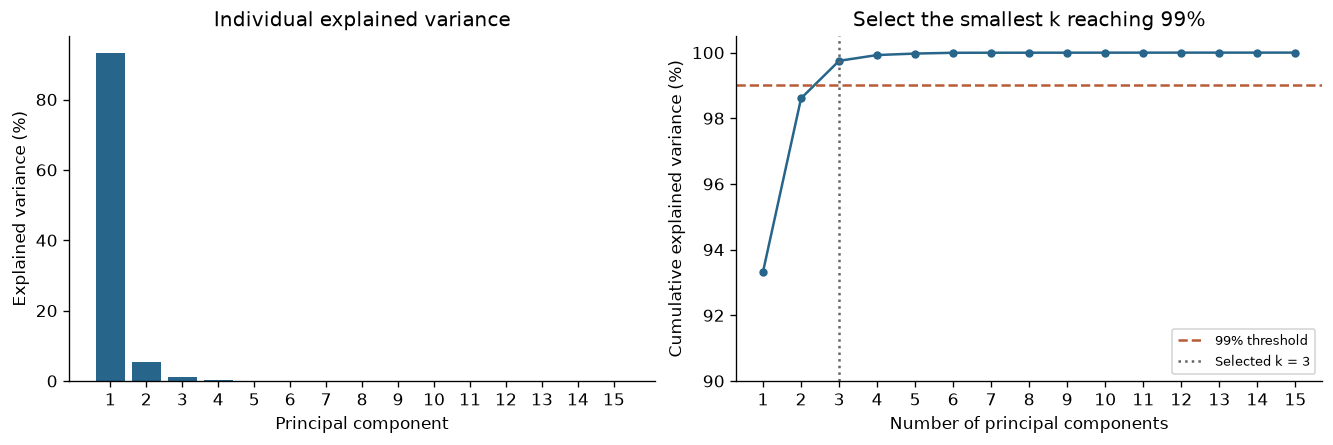

In [3]:
# TODO 1: Prepare the PCA input DataFrame X and fit sklearn PCA.
# Define the fitted pca object and its scores_array.
# PCA input: daily changes of the par swap rates in basis points, using every
# observation on or before the value date (the covariance is then in bp squared).
history = swap_rates.loc[:pd.Timestamp(value_date), tenors]
X = (history.diff().dropna() * 1e4)
X.index.name = "Dates"
pca = PCA()
scores_array = pca.fit_transform(X)

eigenvalues = pca.explained_variance_
explained_ratio = pca.explained_variance_ratio_
variance_target = 0.99
# TODO 2: Calculate cumulative_ratio and select the smallest k reaching variance_target.
cumulative_ratio = np.cumsum(explained_ratio)
k = int(np.argmax(cumulative_ratio >= variance_target) + 1)
pc_names = [f"PC{i + 1}" for i in range(len(eigenvalues))]
selected_pc_names = pc_names[:k]

selected_eigenvalues = pca.explained_variance_[:k]
scores = pd.DataFrame(scores_array, index=X.index, columns=pc_names)
explained_variance = pd.DataFrame({
    "Eigenvalue (bp squared)": eigenvalues,
    "Explained variance": explained_ratio,
    "Cumulative explained variance": cumulative_ratio,
    "Selected": np.arange(len(eigenvalues)) < k,
}, index=pd.Index(pc_names, name="Component"))

print(f"Historical quotes: {len(swap_rates)} dates; PCA observations: {len(X)}.")
print(f"Selected PCs: {k}; cumulative explained variance: {cumulative_ratio[k - 1]:.4%}.")
if k > 1:
    print(f"The first {k - 1} PCs explain {cumulative_ratio[k - 2]:.4%}, below the 99% threshold.")
display(explained_variance.style.format({
    "Eigenvalue (bp squared)": "{:.6f}",
    "Explained variance": "{:.4%}",
    "Cumulative explained variance": "{:.4%}",
}))

positions = np.arange(1, len(eigenvalues) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
axes[0].bar(positions, 100 * explained_ratio, color="#27658b")
axes[0].set(xlabel="Principal component", ylabel="Explained variance (%)",
            title="Individual explained variance", xticks=positions)
axes[1].plot(positions, 100 * cumulative_ratio, "o-", color="#27658b", markersize=4)
axes[1].axhline(100 * variance_target, color="#b85b37", linestyle="--", label="99% threshold")
axes[1].axvline(k, color="#666666", linestyle=":", label=f"Selected k = {k}")
axes[1].set(xlabel="Number of principal components", ylabel="Cumulative explained variance (%)",
            title="Select the smallest k reaching 99%", xticks=positions, ylim=(90, 100.5))
axes[1].legend(fontsize=8, loc="lower right")
plt.show()

## 2. Calibration and Calculate Risk from Yield Curve

Run the provided 2026-02-26 calibration, pricing, and Jacobian quote-risk code (USD/bp), keeping the funding spread at zero.
Use the supplied portfolio risk vector $d$ and assemble $H$ from the hedge quote risks.

In [4]:
funding_index = "SOFR-1B-FLAT"
funding_convention = "SOFR-1B-FLAT-OVER-SOFR-1B-ZERO-SPREAD"
funding_label = "USD-SOFR-FUNDING"

curve_quotes = swap_rates.loc[pd.Timestamp(value_date)].to_frame(name="values")
funding_quotes = pd.DataFrame({"values": [0.0]}, index=["30Y"])
funding_table = pd.DataFrame(
    [
        ["Overnight Index Swap", swap_convention, funding_index],
        ["Spread Zero Rate", funding_convention, funding_index],
    ],
    columns=["DATA TYPE", "DATA CONVENTION", "FUNDING IDENTIFIER"],
)

data_collection = qfCreateDataCollection([
    qfCreateData1D("Overnight Index Swap", swap_convention, curve_quotes),
    qfCreateData1D("Spread Zero Rate", funding_convention, funding_quotes),
    qfCreateDataGeneric("Data Generic", funding_label, funding_table),
])

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod("YIELD_CURVE_COMMON", {
        "TARGET": "USD",
        "FUNDING PARAMETERS": funding_label,
        "SOLVER": "BRENTQ",
    }),
    qfCreateBuildMethod("YIELD_CURVE_FUNDING", {
        "TARGET": funding_index,
        "SPREAD ZERO RATE": funding_convention,
    }),
    qfCreateBuildMethod("YIELD_CURVE_INDEX", {
        "TARGET": "SOFR-1B",
        "OVERNIGHT INDEX SWAP": swap_convention,
    }),
])

yield_curve = qfCreateModel(value_date, "YIELD_CURVE", data_collection, build_methods)
valuation_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": funding_index,
    }),
])
print(f"Yield curve is ready for {value_date}.")

Yield curve is ready for 2026-02-26.


**Portfolio pricing and quote risk**

Forward swaps (spot-date offset × tenor): `1Y×5Y, 1Y×10Y, 5Y×5Y, 5Y×1Y, 5Y×10Y, 10Y×5Y, 10Y×10Y`.
Run the provided code to price each USD 1m receive-fixed swap at its forward par rate and obtain its quote DV01 and aggregate $d$.

In [5]:
portfolio_tenors = [
    "1Yx5Y", "1Yx10Y", "5Yx5Y", "5Yx1Y",
    "5Yx10Y", "10Yx5Y", "10Yx10Y",
]
portfolio_notional = 1e6
portfolio_products = {}
portfolio_rows = []
portfolio_risk_rows = []

for axis in portfolio_tenors:
    # Obtain the forward par rate through the library API.
    trial_swap = qfCreateProductFromDataConvention(
        value_date, swap_convention, axis, 0.04,
        notional=portfolio_notional, pay_or_rec="receive",
    )
    par_rate = float(qfCreateValueReport(
        yield_curve, trial_swap, valuation_parameters, "parrateorspread",
    ))
    product = qfCreateProductFromDataConvention(
        value_date, swap_convention, axis, par_rate,
        notional=portfolio_notional, pay_or_rec="receive",
    )
    pv = dict(qfCreateValueReport(
        yield_curve, product, valuation_parameters, "pv",
    ))["USD"]
    risk_report = qfCreateValueReport(
        yield_curve, product, valuation_parameters, "firstorderrisk",
    ).display()
    portfolio_products[axis] = product
    ois_rows = risk_report.loc[
        (risk_report["DATA_TYPE"].str.upper() == "OVERNIGHT INDEX SWAP")
        & (risk_report["DATA_CONVENTION"] == swap_convention)
    ]
    risk_vector = ois_rows.set_index("AXIS1")["VALUES"].astype(float).reindex(tenors)
    if risk_vector.isna().any():
        raise ValueError(f"Missing OIS quote risk for {axis}.")

    portfolio_rows.append({
        "Swap": axis,
        "Effective date": product.effective_date.ISO(),
        "Termination date": product.termination_date.ISO(),
        "Notional (USD)": product.notional,
        "Par rate": par_rate,
        "Fixed coupon": product.fixed_rate,
        "PV (USD)": float(pv),
    })
    portfolio_risk_rows.append(risk_vector.to_numpy())

portfolio_summary = pd.DataFrame(portfolio_rows).set_index("Swap")
portfolio_risk = pd.DataFrame(portfolio_risk_rows, index=portfolio_tenors, columns=tenors)
portfolio_risk.index.name = "Swap"
d = portfolio_risk.loc[:, tenors].sum(axis=0).to_numpy(dtype=float)
risk_agg = pd.DataFrame([d], columns=tenors, index=pd.Index(["AGG_RISK"], name="Portfolio"))
portfolio_pv = portfolio_summary["PV (USD)"].sum()

print("Portfolio pricing:")
display(portfolio_summary.style.format({
    "Notional (USD)": "{:,.0f}", "Par rate": "{:.6%}",
    "Fixed coupon": "{:.6%}", "PV (USD)": "{:.3e}",
}))
print(f"Total portfolio PV (USD): {portfolio_pv:.6e}")
print("Individual quote DV01s (USD per bp):")
display(portfolio_risk.style.format("{:,.4f}"))
print("Aggregated quote DV01 (USD per bp):")
display(risk_agg.style.format("{:,.4f}"))

Portfolio pricing:


,Effective date,Termination date,Notional (USD),Par rate,Fixed coupon,PV (USD)
Swap,,,,,,
1Yx5Y,2027-02-26,2032-02-26,"1,000,000",3.332391%,3.332391%,0.000e+00
1Yx10Y,2027-02-26,2037-02-26,"1,000,000",3.672308%,3.672308%,-5.821e-11
5Yx5Y,2031-02-26,2036-02-26,"1,000,000",3.946038%,3.946038%,0.000e+00
5Yx1Y,2031-02-26,2032-02-26,"1,000,000",3.677845%,3.677845%,0.000e+00
5Yx10Y,2031-02-26,2041-02-26,"1,000,000",4.172142%,4.172142%,-5.821e-11
10Yx5Y,2036-02-26,2041-02-26,"1,000,000",4.451723%,4.451723%,-2.910e-11
10Yx10Y,2036-02-26,2046-02-26,"1,000,000",4.460380%,4.460380%,-2.910e-11


Total portfolio PV (USD): -1.746230e-10
Individual quote DV01s (USD per bp):


,1Y,2Y,3Y,4Y,5Y,6Y,7Y,8Y,9Y,10Y,12Y,15Y,20Y,25Y,30Y
Swap,,,,,,,,,,,,,,,
1Yx5Y,97.8237,0.0364,0.0549,0.0746,0.0942,-543.0096,-0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1Yx10Y,98.1159,-0.0401,-0.0605,-0.0822,-0.1038,-0.1282,-0.1525,-0.1849,1.8024,-414.9194,-499.1919,0.0000,0.0000,0.0000,0.0000
5Yx5Y,0.2982,0.6094,0.9216,1.2518,461.8607,-1.6520,-1.9663,-2.2585,-2.5831,-847.0534,0.0000,0.0000,0.0000,0.0000,0.0000
5Yx1Y,0.0583,0.1194,0.1804,0.2450,460.5747,-544.8696,0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
5Yx10Y,0.5354,1.0952,1.6551,2.2484,463.1337,-1.3546,-1.6083,-1.8473,-2.1072,-3.5844,-7.5163,"-1,162.3741",0.0000,0.0000,0.0000
10Yx5Y,0.2403,0.4930,0.7436,1.0106,1.2805,1.5697,1.8753,2.1540,2.4739,844.7993,-13.5316,"-1,168.6368",0.0000,0.0000,0.0000
10Yx10Y,0.3633,0.7455,1.1244,1.5281,1.9363,2.3735,2.8357,3.2571,3.7323,846.9138,-9.2649,-19.5840,"-1,424.0250",0.0000,0.0000


Aggregated quote DV01 (USD per bp):


,1Y,2Y,3Y,4Y,5Y,6Y,7Y,8Y,9Y,10Y,12Y,15Y,20Y,25Y,30Y
Portfolio,,,,,,,,,,,,,,,
AGG_RISK,197.4351,3.0588,4.6195,6.2764,"1,388.7764","-1,087.0708",0.9839,1.1203,3.3182,426.1559,-529.5046,"-2,350.5950","-1,424.0250",0.0000,0.0000


**Hedging instruments**

Use 13 spot swaps: `1Y, 2Y, 3Y, 4Y, 5Y, 6Y, 7Y, 8Y, 9Y, 10Y, 12Y, 15Y, 20Y`, each USD 1m receive-fixed at par.
Build $H$ with one column per hedge and all 15 quote tenors as rows, including 25Y and 30Y.

In [6]:
hedge_tenors = [
    "1Y", "2Y", "3Y", "4Y", "5Y", "6Y", "7Y",
    "8Y", "9Y", "10Y", "12Y", "15Y", "20Y",
]
hedge_notional = 1e6
hedge_products = {}
hedge_rows = []
hedge_risk_rows = []

for axis in hedge_tenors:
    trial_swap = qfCreateProductFromDataConvention(
        value_date, swap_convention, axis, 0.04,
        notional=hedge_notional, pay_or_rec="receive",
    )
    par_rate = float(qfCreateValueReport(
        yield_curve, trial_swap, valuation_parameters, "parrateorspread",
    ))
    product = qfCreateProductFromDataConvention(
        value_date, swap_convention, axis, par_rate,
        notional=hedge_notional, pay_or_rec="receive",
    )
    pv = dict(qfCreateValueReport(
        yield_curve, product, valuation_parameters, "pv",
    ))["USD"]
    risk_report = qfCreateValueReport(
        yield_curve, product, valuation_parameters, "firstorderrisk",
    ).display()
    hedge_products[axis] = product
    ois_rows = risk_report.loc[
        (risk_report["DATA_TYPE"].str.upper() == "OVERNIGHT INDEX SWAP")
        & (risk_report["DATA_CONVENTION"] == swap_convention)
    ]
    risk_vector = ois_rows.set_index("AXIS1")["VALUES"].astype(float).reindex(tenors)
    if risk_vector.isna().any():
        raise ValueError(f"Missing OIS quote risk for {axis}.")

    hedge_rows.append({"Tenor": axis, "Par rate": par_rate, "PV (USD)": float(pv)})
    hedge_risk_rows.append(risk_vector.to_numpy())

hedge_summary = pd.DataFrame(hedge_rows).set_index("Tenor")
hedging = pd.DataFrame(hedge_risk_rows, index=hedge_tenors, columns=tenors)
hedging.index.name = "Hedge tenor"
# TODO 3: Build H from hedging, with quote tenors as rows and hedge instruments as columns.
H = hedging.loc[hedge_tenors, tenors].to_numpy(dtype=float).T  # (15 quote tenors) x (13 hedges)

print("Reference hedge swaps: USD 1,000,000 each, receive fixed at par.")
display(hedge_summary.style.format({"Par rate": "{:.6%}", "PV (USD)": "{:.3e}"}))
print("Hedging instruments' quote DV01s (USD per bp):")
display(hedging.style.format("{:,.4f}"))
print(f"Portfolio risk shape: {d.shape}; hedge risk matrix H shape: {H.shape}.")

Reference hedge swaps: USD 1,000,000 each, receive fixed at par.


,Par rate,PV (USD)
Tenor,,
1Y,3.452800%,0.000e+00
2Y,3.260100%,1.455e-11
3Y,3.224200%,1.455e-11
4Y,3.249100%,1.455e-11
5Y,3.295800%,0.000e+00
6Y,3.354100%,2.910e-11
7Y,3.415700%,-2.910e-11
8Y,3.476200%,8.731e-11
9Y,3.534600%,0.000e+00


Hedging instruments' quote DV01s (USD per bp):


,1Y,2Y,3Y,4Y,5Y,6Y,7Y,8Y,9Y,10Y,12Y,15Y,20Y,25Y,30Y
Hedge tenor,,,,,,,,,,,,,,,
1Y,-97.9226,-0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2Y,0.0000,-193.4733,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3Y,0.0000,-0.0000,-285.2149,-0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4Y,-0.0000,-0.0000,0.0000,-374.2559,-0.0000,0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
5Y,-0.0000,0.0000,-0.0000,-0.0000,-460.2455,0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
6Y,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,-543.1265,-0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
7Y,0.0000,-0.0000,0.0000,0.0000,-0.0000,0.0000,-623.5882,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
8Y,0.0000,0.0000,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,-700.0441,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
9Y,0.0000,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,-773.4814,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


Portfolio risk shape: (15,); hedge risk matrix H shape: (15, 13).


## 3. PC Loadings and Risk Exposures

Display and plot the retained PC loadings $U_k$ across the original swap tenors.
Calculate portfolio and hedge PC exposures, then reconstruct portfolio risk in quote space.

Selected PC loadings on the original swap-rate tenors:


,PC1,PC2,PC3
Original quote tenor,,,
1Y,0.192703,0.374995,0.709287
2Y,0.242617,0.404067,0.290924
3Y,0.264969,0.329337,-0.088012
4Y,0.272410,0.255275,-0.207128
5Y,0.278147,0.176268,-0.268576
6Y,0.278312,0.102516,-0.245654
7Y,0.277903,0.032249,-0.200233
8Y,0.274747,-0.021433,-0.158687
9Y,0.272636,-0.068205,-0.118655


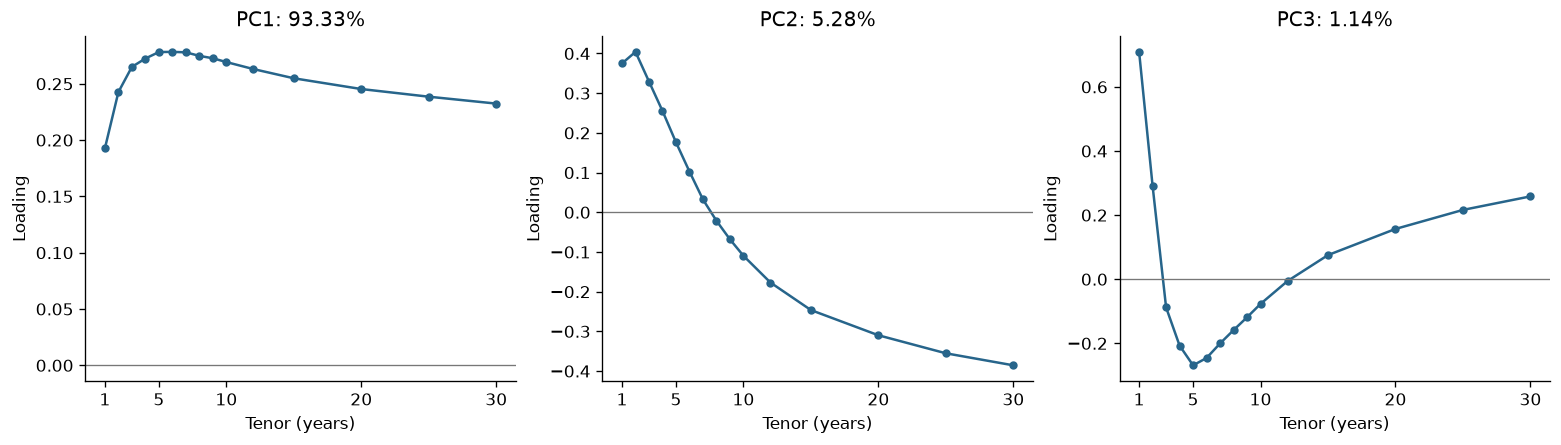

In [7]:
# TODO 4: Extract U_k from the fitted pca, with one retained PC loading vector per column.
U_k = pca.components_[:k].T  # (15 quote tenors) x (k retained PCs)

loadings = pd.DataFrame(
    U_k, index=pd.Index(tenors, name="Original quote tenor"), columns=selected_pc_names,
)
print("Selected PC loadings on the original swap-rate tenors:")
display(loadings.style.format("{:.6f}"))

fig, axes = plt.subplots(1, k, figsize=(4.3 * k, 3.6), constrained_layout=True, squeeze=False)
for j, ax in enumerate(axes.ravel()):
    ax.plot(tenor_years, U_k[:, j], "o-", color="#27658b", markersize=4)
    ax.axhline(0.0, color="#777777", linewidth=0.8)
    ax.set(xlabel="Tenor (years)", ylabel="Loading", xticks=[1, 5, 10, 20, 30],
           title=f"PC{j + 1}: {explained_ratio[j]:.2%}")
plt.show()

**Portfolio and hedge risks in PC space**

Calculate and report $g=U_k^Td$ and $A=U_k^TH$, keeping the original quote-tenor order aligned.

In [8]:
# TODO 5: Calculate portfolio PC exposures g and hedge PC exposures A.
g = U_k.T @ d  # (k,)   portfolio PC exposures
A = U_k.T @ H  # (k, 13) hedge PC exposures

portfolio_pc_risk = pd.DataFrame({
    "Portfolio exposure g": g,
}, index=pd.Index(selected_pc_names, name="Component"))
hedge_pc_risk = pd.DataFrame(
    A.T,
    index=hedge_tenors,
    columns=selected_pc_names,
)

print("Portfolio PC risk g (USD per bp of unit PC):")
display(portfolio_pc_risk.style.format("{:,.6f}"))
print("Reference hedge instruments' PC risks (rows of A.T, USD per bp of unit PC):")
display(hedge_pc_risk.style.format("{:,.6f}"))

Portfolio PC risk g (USD per bp of unit PC):


,Portfolio exposure g
Component,
PC1,-846.003931
PC2,"1,278.670795"
PC3,-397.904583


Reference hedge instruments' PC risks (rows of A.T, USD per bp of unit PC):


,PC1,PC2,PC3
1Y,-18.870006,-36.720466,-69.455214
2Y,-46.939936,-78.176220,-56.286072
3Y,-75.573222,-93.931884,25.102406
4Y,-101.951138,-95.538170,77.518715
5Y,-128.015920,-81.126325,123.610726
6Y,-151.158626,-55.679032,133.421012
7Y,-173.296869,-20.110335,124.863221
8Y,-192.335283,15.003969,111.087616
9Y,-210.878524,52.754995,91.777375
10Y,-227.281691,92.527541,64.913769


**Reconstruct the portfolio risk**

Tabulate $d$, its projection $\widehat d=U_kg$, and the residual $d_\perp=d-\widehat d$; plot $d$ and $\widehat d$.

Risk reconstruction before hedging (USD per bp):


,Original quote DV01 d,Projected risk d_hat,Projection residual d_perp
Tenor,,,
1Y,197.4351,34.2387,163.1964
2Y,3.0588,195.6538,-192.5950
3Y,4.6195,231.9692,-227.3498
4Y,6.2764,178.3696,-172.0931
5Y,"1,388.7764",96.9421,"1,291.8343"
6Y,"-1,087.0708",-6.6224,"-1,080.4484"
7Y,0.9839,-114.1967,115.1806
8Y,1.1203,-196.7009,197.8212
9Y,3.3182,-270.6486,273.9668


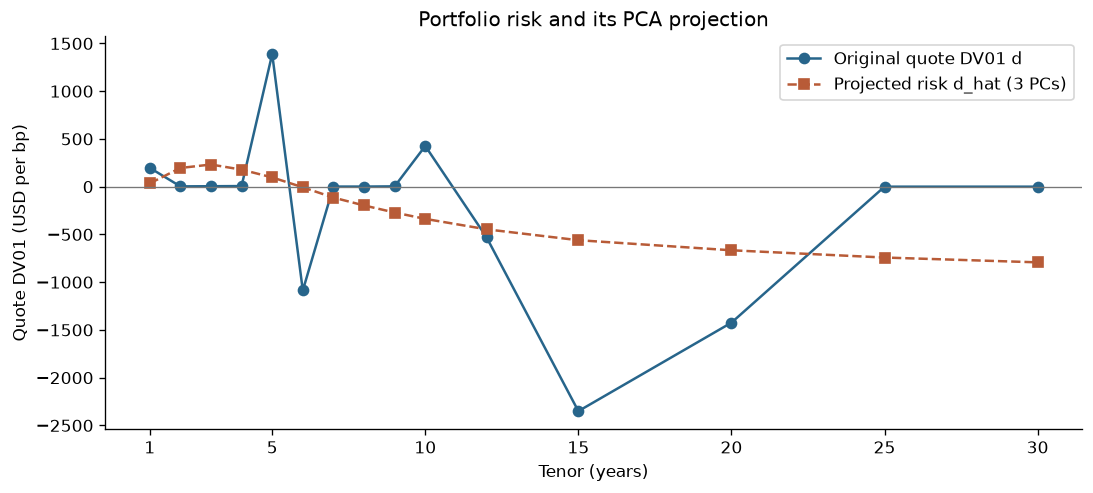

In [9]:
# TODO 6: Calculate the projected risk d_hat and projection residual d_perp.
d_hat = U_k @ g
d_perp = d - d_hat

risk_reconstruction = pd.DataFrame({
    "Original quote DV01 d": d,
    "Projected risk d_hat": d_hat,
    "Projection residual d_perp": d_perp,
}, index=pd.Index(tenors, name="Tenor"))

print("Risk reconstruction before hedging (USD per bp):")
display(risk_reconstruction.style.format("{:,.4f}"))

fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
ax.plot(tenor_years, d, "o-", color="#27658b", label="Original quote DV01 d")
ax.plot(tenor_years, d_hat, "s--", color="#b85b37", label=f"Projected risk d_hat ({k} PCs)")
ax.axhline(0.0, color="#777777", linewidth=0.8)
ax.set(xlabel="Tenor (years)", ylabel="Quote DV01 (USD per bp)",
       title="Portfolio risk and its PCA projection", xticks=[1, 5, 10, 15, 20, 25, 30])
ax.legend()
plt.show()

## 4. PCA Unweighted Least Squares

Solve $\min_w\lVert Aw+g\rVert_2^2$ with `np.linalg.lstsq`, selecting the minimum-norm solution.
Report each hedge instrument's weight, signed notional, and fixed-leg direction.

In [10]:
# TODO 7: Calculate the minimum-norm unweighted hedge positions w_unweighted.
# min_w ||A w + g||_2^2  <=>  A w = -g ; lstsq returns the minimum-norm solution
w_unweighted, *_ = np.linalg.lstsq(A, -g, rcond=None)

unweighted_hedge = pd.DataFrame({
    "Weight": w_unweighted,
    "Signed notional (USD)": hedge_notional * w_unweighted,
    "Fixed-leg direction": np.where(w_unweighted >= 0.0, "Receive fixed", "Pay fixed"),
}, index=pd.Index(hedge_tenors, name="Hedge tenor"))
display(unweighted_hedge.style.format({"Weight": "{:.9f}", "Signed notional (USD)": "{:,.2f}"}))

,Weight,Signed notional (USD),Fixed-leg direction
Hedge tenor,,,
1Y,0.486316169,"486,316.17",Receive fixed
2Y,0.758440926,"758,440.93",Receive fixed
3Y,0.653778704,"653,778.70",Receive fixed
4Y,0.547197965,"547,197.96",Receive fixed
5Y,0.358924671,"358,924.67",Receive fixed
6Y,0.210253046,"210,253.05",Receive fixed
7Y,0.053890978,"53,890.98",Receive fixed
8Y,-0.088863988,"-88,863.99",Pay fixed
9Y,-0.231686532,"-231,686.53",Pay fixed


## 5. PCA Weighted Least Squares

Solve $\min_w\lVert\Lambda_k^{1/2}(Aw+g)\rVert_2^2$ using the retained PCA eigenvalues and minimum-norm least squares.
Report each hedge instrument's weight, signed notional, and fixed-leg direction.

In [11]:
# TODO 8: Use the retained PCA eigenvalues to calculate the minimum-norm hedge positions w_weighted.
# min_w ||Lambda_k^{1/2} (A w + g)||_2^2 : scale each PC row by sqrt(eigenvalue)
sqrt_lambda = np.sqrt(selected_eigenvalues)
A_weighted = sqrt_lambda[:, None] * A
g_weighted = sqrt_lambda * g
w_weighted, *_ = np.linalg.lstsq(A_weighted, -g_weighted, rcond=None)

weighted_hedge = pd.DataFrame({
    "Weight": w_weighted,
    "Signed notional (USD)": hedge_notional * w_weighted,
    "Fixed-leg direction": np.where(w_weighted >= 0.0, "Receive fixed", "Pay fixed"),
}, index=pd.Index(hedge_tenors, name="Hedge tenor"))
display(weighted_hedge.style.format({"Weight": "{:.9f}", "Signed notional (USD)": "{:,.2f}"}))

,Weight,Signed notional (USD),Fixed-leg direction
Hedge tenor,,,
1Y,0.486316169,"486,316.17",Receive fixed
2Y,0.758440926,"758,440.93",Receive fixed
3Y,0.653778704,"653,778.70",Receive fixed
4Y,0.547197965,"547,197.96",Receive fixed
5Y,0.358924671,"358,924.67",Receive fixed
6Y,0.210253046,"210,253.05",Receive fixed
7Y,0.053890978,"53,890.98",Receive fixed
8Y,-0.088863988,"-88,863.99",Pay fixed
9Y,-0.231686532,"-231,686.53",Pay fixed
